# FGVC-Aircraft: an unseen dataset, end to end on the GPU

The project's selectors were built and tuned on two datasets, SCAN-B gene
expression and BreastMNIST ultrasound embeddings. This notebook takes a
third dataset that played no part in that work, from a different domain,
and runs the whole pipeline on it on the GPU: embedding, selection, and
the same evaluation protocol.

**The data.** FGVC-Aircraft 2013b (Maji et al. 2013, arXiv:1306.5151):
10,000 photos of aircraft, 100 per model variant. The task is binary, as
everywhere in this project: **Boeing 737** (8 variants, 800 photos)
against the **Airbus A320 family** (A318, A319, A320, A321; 400 photos).
Both are narrow-body twin-engine airliners that look alike, so the task is
not trivial.

**Why this dataset.**

- Not medical, not genes: aircraft photos.
- More features than training samples after embedding: 2,048 ResNet-50
  features, 840 training images per split.
- Almost no overlap with ImageNet's training images (Kornblith et al. 2019,
  arXiv:1805.08974, Table H.1), so the pretrained network has not seen
  these photos.
- Clean labels, exactly 100 images per variant.

**Licence.** The images are for non-commercial research only. The loader
downloads them; they are not in the repository.

**Pipeline.** `featsel_datasets/fgvc_aircraft/`: a class that downloads the
2.75 GB archive once and reads it in one pass without unpacking it, and a
`featsel_view.py` with the task. The experiment is
`configs/aircraft70_gpu.yaml`, run with
`python -m featsel.run --config configs/aircraft70_gpu.yaml --n-jobs 1`.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd().parents[2]
sys.path.insert(0, str(ROOT))  # repo root, so featsel_datasets imports

from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.preprocessing import StandardScaler

from featsel.analysis import kuncheva_index
from featsel.selectors import HigherCriticismSelector, MannWhitneySelector
from featsel.selectors.log_pvalue import log_mannwhitneyu
from featsel_datasets.fgvc_aircraft.aircraft import FGVCAircraft
from featsel_datasets.fgvc_aircraft.featsel_view import load_xy

print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none')

GPU: NVIDIA GeForce GTX 1650


## 1. The data

The first call downloads the archive (2.75 GB) and embeds all 10,000 images
on the GPU, about 4 minutes on a GTX 1650. Later calls read the cache.

In [2]:
data = FGVCAircraft()
X, y = load_xy(data)
print(f'{X.shape[0]} images x {X.shape[1]} features')
print(y.value_counts().to_string())
data.samples.loc[y.index].groupby(['family', 'variant']).size().to_frame('images')

1200 images x 2048 features
family
Boeing 737    800
A320          400


images
family     variant        
A320       A318        100
           A319        100
           A320        100
           A321        100
Boeing 737 737-200     100
           737-300     100
           737-400     100
           737-500     100
           737-600     100
           737-700     100
           737-800     100
           737-900     100

In [ ]:
examples = ['Boeing 737', 'Boeing 737', 'A320', 'A320']
ids = [y.index[y == f][i * 37] for i, f in enumerate(examples)]
images = data.images(ids)
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, image in zip(axes, ids):
    ax.imshow(images[image])
    ax.set_title(f"{data.samples.loc[image, 'variant']} ({image})", fontsize=9)
    ax.axis('off')
plt.tight_layout()

## 2. What the features look like

Each image is cropped of its 20-pixel copyright banner, resized to 256,
centre-cropped to 224 and passed through ResNet-50 without its last layer.
The result is 2,048 average-pooled features.

**V1, not V2 weights.** BreastMNIST used torchvision's `IMAGENET1K_V2`
weights. On this task V2's features were 80% exact zeros and reached AUC
0.749 with all features. `IMAGENET1K_V1` gave 0.1% zeros and 0.863, so the
aircraft loader uses V1. (Measured once on all 1,200 images, logistic
regression with C = 0.01, five 70/30 splits; see the loader's docstring.)

In [4]:
values = X.to_numpy()
corr = np.corrcoef(StandardScaler().fit_transform(values), rowvar=False)
upper = np.abs(corr[np.triu_indices_from(corr, 1)])
pca = PCA().fit(StandardScaler().fit_transform(values))
cum = np.cumsum(pca.explained_variance_ratio_)

log_p, auc, device = log_mannwhitneyu(values, y.to_numpy(), 'cuda', return_device=True)
p = np.exp(log_p)
order = np.sort(p)
bh = order <= 0.05 * np.arange(1, len(p) + 1) / len(p)
n_bh = int(np.nonzero(bh)[0].max() + 1) if bh.any() else 0

facts = {
    'images': len(values),
    'features': values.shape[1],
    'values exactly zero': f'{(values == 0).mean():.1%}',
    'median |correlation| between two features': f'{np.median(upper):.3f}',
    'feature pairs with |correlation| > 0.5': f'{(upper > 0.5).mean():.2%}',
    'principal components for 50% / 90% / 99% of variance':
        ' / '.join(str(int(np.searchsorted(cum, q) + 1)) for q in (0.5, 0.9, 0.99)),
    'features passing the U test at 5% FDR (all images)': f'{n_bh / len(p):.0%}',
    'best single-feature AUC': f'{np.max(np.maximum(auc, 1 - auc)):.3f}',
    'U test ran on': device,
}
pd.Series(facts).to_frame('value')

,value
images,1200
features,2048
values exactly zero,0.1%
median |correlation| between two features,0.111
feature pairs with |correlation| > 0.5,0.23%
principal components for 50% / 90% / 99% of variance,17 / 166 / 652
features passing the U test at 5% FDR (all images),36%
best single-feature AUC,0.690
U test ran on,cuda


The U-test share above uses all 1,200 images, so it describes the data,
not a selection: the experiment below selects inside each training split
only.

### Near-duplicate images

BreastMNIST turned out to hold copied images, some with different labels,
which leak across a train/test split. So we check here before trusting any
score. Each image has a 64-bit difference hash (a 9 × 8 grayscale
thumbnail, one bit per horizontal step). Copies differ by a few bits at
most. We also compare the embeddings themselves by cosine similarity.

In [5]:
hashes = data.hashes.loc[y.index].astype(np.uint64).to_numpy()
bits = np.unpackbits(hashes.view(np.uint8).reshape(-1, 8), axis=1).astype(bool)
distance = (bits[:, None, :] != bits[None, :, :]).sum(axis=2)
upper_pairs = np.triu(np.ones_like(distance, dtype=bool), 1)
for t in (0, 2, 4, 6, 8):
    pairs = np.argwhere((distance <= t) & upper_pairs)
    mixed = sum(y.iloc[a] != y.iloc[b] for a, b in pairs)
    print(f'hash distance <= {t}: {len(pairs):3d} pairs, {mixed} with different labels')

emb = StandardScaler().fit_transform(values)
emb /= np.linalg.norm(emb, axis=1, keepdims=True)
cos = emb @ emb.T
np.fill_diagonal(cos, -1)
a, b = np.unravel_index(np.argmax(cos), cos.shape)
print(f'highest cosine similarity between two images: {cos[a, b]:.3f} '
      f'({y.index[a]}, {y.index[b]})')

hash distance <= 0:   0 pairs, 0 with different labels
hash distance <= 2:   0 pairs, 0 with different labels
hash distance <= 4:   0 pairs, 0 with different labels
hash distance <= 6:   4 pairs, 2 with different labels
hash distance <= 8:  33 pairs, 4 with different labels
highest cosine similarity between two images: 0.864 (0223783, 0221294)


In [ ]:
pairs = np.argwhere((distance <= 6) & upper_pairs)
if len(pairs):
    shown = pairs[:4]
    pics = data.images([y.index[i] for pair in shown for i in pair])
    fig, axes = plt.subplots(len(shown), 2, figsize=(7, 2.2 * len(shown)), squeeze=False)
    for row, (i, j) in zip(axes, shown):
        for ax, k in zip(row, (i, j)):
            ax.imshow(pics[y.index[k]])
            ax.set_title(f'{y.index[k]}: {y.iloc[k]}', fontsize=9)
            ax.axis('off')
    plt.tight_layout()

**No copies.** The closest pairs by hash show different aircraft:
different airlines and liveries, photographed side-on against a similar
sky. A 64-bit hash of a 9 × 8 thumbnail cannot tell such shots apart. The
embeddings agree: the most similar pair has cosine similarity 0.86, far
from the near 1.0 of a copy. Unlike BreastMNIST, nothing here leaks
across a split.

The photos in this section are not stored in the notebook: the licence allows non-commercial research use only, and this repository is public. Run the notebook to see them.

## 3. One selection on the GPU, step by step

Before the full experiment, one split by hand. The data goes to the GPU
once as a PyTorch tensor. A selector given a GPU tensor runs there, and
its `transform` returns a GPU tensor, so the selected features never leave
the GPU.

In [7]:
split = StratifiedShuffleSplit(1, train_size=0.7, random_state=42)
train, test = next(split.split(values, y))
scaler = StandardScaler().fit(values[train])
X_train = torch.tensor(scaler.transform(values[train]), dtype=torch.float32, device='cuda')
X_test = torch.tensor(scaler.transform(values[test]), dtype=torch.float32, device='cuda')
y_train, y_test = y.to_numpy()[train], y.to_numpy()[test]

for selector in (MannWhitneySelector(n_features=250), HigherCriticismSelector()):
    selector.fit(X_train, y_train)          # warm-up: loads the GPU kernels
    torch.cuda.synchronize()
    start = time.perf_counter()
    selector.fit(X_train, y_train)
    torch.cuda.synchronize()
    seconds = time.perf_counter() - start
    Z_train, Z_test = selector.transform(X_train), selector.transform(X_test)
    model = LogisticRegression(max_iter=1000).fit(Z_train.cpu().numpy(), y_train)
    positive = list(model.classes_).index('Boeing 737')
    score = roc_auc_score(y_test == 'Boeing 737',
                          model.predict_proba(Z_test.cpu().numpy())[:, positive])
    print(f'{type(selector).__name__:26s} device={selector.device_:5s} '
          f'kept {int(selector.get_support().sum()):4d} features in {seconds*1000:6.1f} ms, '
          f'output on {Z_train.device}, test AUC {score:.3f}')

MannWhitneySelector        device=cuda:0 kept  250 features in    6.6 ms, output on cuda:0, test AUC 0.795
HigherCriticismSelector    device=cuda:0 kept  204 features in    7.3 ms, output on cuda:0, test AUC 0.818


## 4. The full experiment

`configs/aircraft70_gpu.yaml`: 10 stratified random splits, 70% of the
images for training (840), standardization fit on the training part,
logistic regression (C = 1) as the classifier, ROC AUC on the test part.
Every selector runs with `device='cuda'`:

- filters: Mann-Whitney, Higher Criticism (HC2008), Spearman correlation,
  mutual information;
- embedded: Lasso with the PPDNA solver;
- wrappers: RFE and RFECV with the exact Newton SVM solver, Sequential
  forward selection with the batched Newton solver;
- the random control, and random at k = 2,048: every feature, no selection.

Each selection is timed as the median of 3 fits. The run took 5 minutes:
290 executions, one worker.

In [8]:
results = pd.read_csv(ROOT / 'results' / 'aircraft70_gpu.csv')
results['method'] = results['selector'].str.removesuffix('Selector')
print(results.groupby('method')['selection_device'].agg(lambda d: ', '.join(sorted(set(d)))).to_string())

method
Correlation          cuda
HC2008               cuda
Lasso_ppdna          cuda
MannWhitney          cuda
MutualInfo           cuda
RFECV_newton_auc     cuda
RFE_newton           cuda
Random                cpu
Sequential_newton    cuda


In [9]:
per_split = results.groupby(['method', 'k', 'split'], dropna=False)['roc_auc'].mean()
table = per_split.groupby(['method', 'k'], dropna=False).agg(['mean', 'std']).reset_index()
table['k'] = table['k'].map(lambda k: 'own' if pd.isna(k) else int(k))
auc = table.pivot(index='method', columns='k', values='mean')
auc = auc[[c for c in [5, 10, 50, 250, 500, 2048, 'own'] if c in auc.columns]]
auc.round(3)

k,5,10,50,250,500,2048,own
method,,,,,,,
Correlation,NaN,0.726,0.767,0.812,0.829,NaN,NaN
HC2008,NaN,NaN,NaN,NaN,NaN,NaN,0.815
Lasso_ppdna,NaN,0.721,0.784,0.845,0.848,NaN,NaN
MannWhitney,NaN,0.726,0.767,0.812,0.836,NaN,NaN
MutualInfo,NaN,0.712,0.750,0.797,0.829,NaN,NaN
RFECV_newton_auc,NaN,NaN,NaN,NaN,NaN,NaN,0.859
RFE_newton,NaN,0.712,0.785,0.843,0.857,NaN,NaN
Random,NaN,0.608,0.712,0.790,0.819,0.864,NaN
Sequential_newton,0.698,0.698,NaN,NaN,NaN,NaN,NaN


Mean test AUC over 10 splits. `own` is a method that picks its own count
(HC2008, RFECV). Random at 2,048 is all features.

In [10]:
counts = results.groupby(['method', 'k'], dropna=False)['n_selected'].agg(['min', 'median', 'max'])
counts[counts['min'] != counts['max']]

,,min,median,max
method,k,,,
Correlation,500.0,385,425.0,452
Lasso_ppdna,500.0,295,315.5,329
RFECV_newton_auc,NaN,620,824.0,1844


Rows shown only where the number of features kept varies across splits.
Lasso keeps only features with a non-zero weight, so it can keep fewer
than `k`; correlation drops one of each highly correlated pair.

### Gain over random selection, split by split

Each method's AUC minus the random control's, on the same split and at
the same `k`. Paired this way, the split-to-split noise cancels.

In [11]:
fixed = results[results['k'].isin([10, 50, 250, 500])]
wide = fixed.pivot_table(index=['split', 'k'], columns='method', values='roc_auc')
gain = wide.sub(wide['Random'], axis=0).drop(columns='Random')
summary = gain.groupby('k').agg(['mean', 'min'])
wins = (gain > 0).where(gain.notna()).groupby('k').sum(min_count=1)
print('mean gain over random (and the worst split):')
print(pd.concat({m: summary[m]['mean'].round(3).astype(str) + ' (' + summary[m]['min'].round(3).astype(str) + ')'
                 for m in gain.columns}, axis=1).to_string())
print('\nsplits (of 10) where the method beats random:')
print(wins.to_string())

mean gain over random (and the worst split):
          Correlation    Lasso_ppdna     MannWhitney      MutualInfo     RFE_newton Sequential_newton
k                                                                                                    
10.0    0.118 (0.041)  0.113 (0.026)   0.118 (0.041)   0.104 (0.017)  0.104 (0.054)      0.09 (0.029)
50.0    0.055 (0.007)  0.073 (0.005)   0.055 (0.007)   0.038 (0.008)  0.073 (0.016)               NaN
250.0  0.022 (-0.003)   0.055 (0.03)  0.021 (-0.003)  0.006 (-0.028)  0.053 (0.024)               NaN
500.0   0.01 (-0.031)  0.029 (0.003)  0.017 (-0.017)   0.01 (-0.035)  0.038 (0.009)               NaN

splits (of 10) where the method beats random:
method  Correlation  Lasso_ppdna  MannWhitney  MutualInfo  RFE_newton Sequential_newton
k                                                                                      
10.0             10           10           10          10          10                10
50.0             10           10

### Cost against quality

Selection time per fit (log scale) against test AUC, every method and `k`
on one plot, as in chapter 8 of the report. The blue points are the
frontier: no other point is both faster and better. The dashed line is
all 2,048 features.

,method,k,roc_auc,roc_auc_std,selection_time_s,on_frontier
22,Random,10.0,0.6083,0.0374,0.0007,True
23,Random,50.0,0.7119,0.0269,0.0009,True
24,Random,250.0,0.7902,0.0311,0.0013,True
25,Random,500.0,0.8190,0.0255,0.0013,True
4,HC2008,NaN,0.8153,0.0253,0.0141,False
11,MannWhitney,250.0,0.8115,0.0283,0.0172,False
10,MannWhitney,50.0,0.7669,0.0182,0.0172,False
9,MannWhitney,10.0,0.7261,0.0274,0.0172,False
12,MannWhitney,500.0,0.8365,0.0170,0.0172,True
3,Correlation,500.0,0.8288,0.0194,0.0228,False


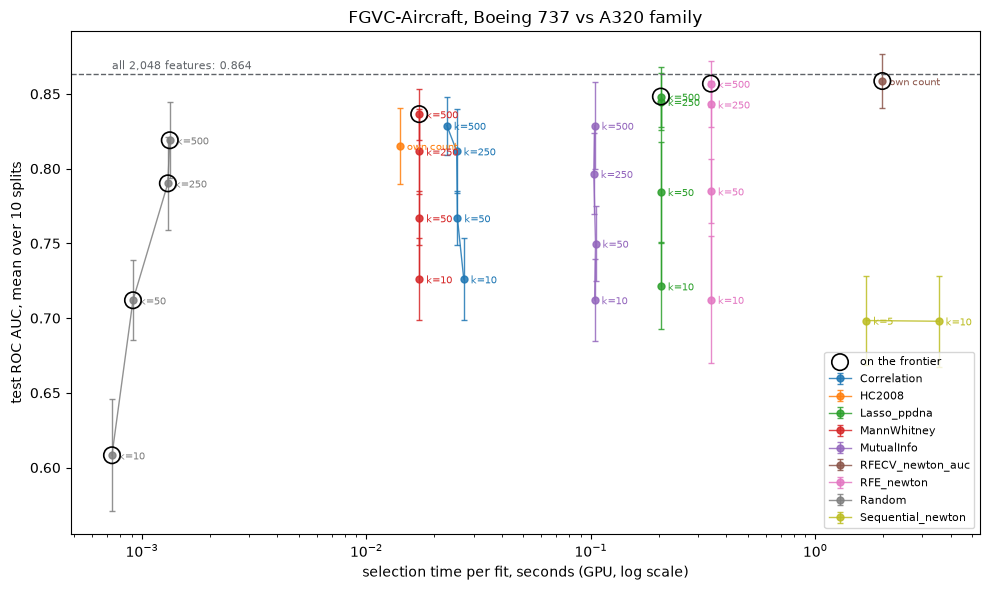

In [12]:
selected = results[~((results['selector'] == 'RandomSelector') & (results['k'] == 2048))]
fits = selected.drop_duplicates(['split', 'selector', 'k'])
points = (selected.groupby(['method', 'k', 'split'], dropna=False)['roc_auc'].mean()
          .groupby(['method', 'k'], dropna=False).agg(roc_auc='mean', roc_auc_std='std')
          .join(fits.groupby(['method', 'k'], dropna=False)['selection_time_s'].median())
          .reset_index())
best = -np.inf
on = pd.Series(False, index=points.index)
for i, row in points.sort_values(['selection_time_s', 'roc_auc'], ascending=[True, False]).iterrows():
    if row['roc_auc'] > best:      # nothing faster scores as well
        on[i], best = True, row['roc_auc']
all_features = per_split.loc[('Random', 2048.0)].mean()

fig, ax = plt.subplots(figsize=(10, 6))
colours = plt.get_cmap('tab10').colors
for colour, (method, part) in zip(colours, points.groupby('method')):
    part = part.sort_values('k')
    ax.errorbar(part['selection_time_s'], part['roc_auc'], yerr=part['roc_auc_std'],
                fmt='o-', color=colour, alpha=0.85, capsize=2, ms=5, lw=1, label=method)
    for _, row in part.iterrows():
        text = 'own count' if pd.isna(row['k']) else f"k={int(row['k'])}"
        ax.annotate(text, (row['selection_time_s'], row['roc_auc']), fontsize=7,
                    xytext=(5, -3), textcoords='offset points', color=colour)
ax.scatter(points.loc[on, 'selection_time_s'], points.loc[on, 'roc_auc'], s=140,
           facecolors='none', edgecolors='black', lw=1.2, label='on the frontier', zorder=3)
ax.axhline(all_features, ls='--', color='#5f6368', lw=1)
ax.text(points['selection_time_s'].min(), all_features + 0.003, f'all 2,048 features: {all_features:.3f}',
        fontsize=8, color='#5f6368')
ax.set_xscale('log')
ax.set_xlabel('selection time per fit, seconds (GPU, log scale)')
ax.set_ylabel('test ROC AUC, mean over 10 splits')
ax.set_title('FGVC-Aircraft, Boeing 737 vs A320 family')
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
points.assign(on_frontier=on).sort_values('selection_time_s').round(4)

### Stability

Kuncheva's index between the feature sets of two splits, averaged over the
45 pairs: 1 means the same features on every split, 0 the overlap expected
by chance. Where a method keeps different numbers of features on
different splits (Lasso, correlation), the index uses the mean size of
each pair, so it is approximate there.

In [13]:
stable = kuncheva_index(results[results['k'].isin([10, 50, 250, 500])], X.shape[1])
stable['method'] = stable['selector'].str.removesuffix('Selector')
stable.pivot_table(index='method', columns='k', values='consistency_index').round(2)

k,10.0,50.0,250.0,500.0
method,,,,
Correlation,0.66,0.76,0.73,0.73
Lasso_ppdna,0.25,0.28,0.32,0.33
MannWhitney,0.66,0.76,0.73,0.74
MutualInfo,0.21,0.23,0.25,0.28
RFE_newton,0.15,0.20,0.29,0.32
Random,-0.00,0.00,0.00,-0.00
Sequential_newton,0.07,NaN,NaN,NaN


## Conclusions

**1. The pipeline handled an unseen dataset unchanged.** Adding it took a
loader folder with two files and one config. Nothing in the `featsel`
package changed. The same selectors, protocol and runner gave the results
above.

**2. The whole pipeline ran on the GPU.** Embedding all 10,000 images took
about 4 minutes. The experiment took 5 minutes: 290 executions, every
selector with `device='cuda'`. Only the random control ran on the CPU; it
draws indices and touches no data. The classifier, scikit-learn's logistic
regression, also runs on the CPU.

**3. The data is clean.** No two images are copies, unlike BreastMNIST.
Every variant has exactly 100 images. So no result here carries a
train/test leak.

**4. The task is hard, and its signal is spread thin.** All 2,048 features
reach AUC 0.864. The best single feature reaches only 0.690. Yet 36% of the
features pass the U test at a 5% false discovery rate. Features are weakly
correlated (median |r| 0.11), and 166 principal components hold 90% of the
variance. This is the same picture as BreastMNIST: many weak features, no
few strong ones.

**5. Selection pays most when few features are allowed.** At k = 10 every
method beats random selection on all 10 splits, by 0.09 to 0.12 AUC. The
gain shrinks as k grows. At k = 500 the filters beat random on only 7 or 8
of the 10 splits.

**6. Methods that see features together win at larger k.** At k = 250 and
500, RFE (0.857 at 500) and Lasso (0.848) score above Mann-Whitney
(0.836), correlation and mutual information (0.829). They beat random on
every split at every k. The one-at-a-time filters cannot, because a
combination of weak features carries more than the best single ones. This
matches BreastMNIST, and differs from SCAN-B, where strong single genes
exist.

**7. No selection is still best for AUC.** All 2,048 features give 0.864.
RFECV scored by AUC comes closest, 0.859, but it keeps 620 to 1,844
features. RFE at k = 500 gives 0.857 with a quarter of the features. Here,
as on the other two datasets, selection buys a smaller model, not a better
one.

**8. Higher Criticism again stopped at the edge of its search.** It kept
204 features, which is 0.1 × 2,048, on every split. The signal is not rare,
so HC acts as a top-10% filter (0.815, the same as Mann-Whitney at about
that size).

**9. The filters are the most stable.** Mann-Whitney and Spearman
correlation choose largely the same features on every split (Kuncheva
index 0.66 to 0.76). Lasso, mutual information and RFE choose mostly
different ones (0.15 to 0.33), with similar scores. Sequential selection is
the least stable (0.07) and the weakest: 0.698 at both 5 and 10 features.

**10. On the GPU, every method is cheap at this size.** The filters take
14 to 27 ms per fit, mutual information 0.10 s, Lasso 0.20 s, RFE 0.34 s
and RFECV 2.0 s. Sequential selection is the slowest, 1.7 to 3.5 s, and the
weakest. The frontier holds random selection, Mann-Whitney at k = 500,
Lasso and RFE at k = 500, and RFECV.

**11. The pretrained network mattered more than the selector.** Changing
ResNet-50's weights from V2 to V1 raised the all-features AUC from 0.749 to
0.863. No selector moved AUC by a tenth of that at k = 500. Checking the
embedding comes before choosing a selector.

**Limits.** One binary task, from one dataset. Ten splits, with no
significance tests. The classifier's C is fixed at 1, not tuned. The images
are licensed for non-commercial research only.
